In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from autoencoder import Autoencoder
from data import make_data


labeled pictures:
O013257.npz
O013490.npz
O012791.npz

In [3]:
df = pd.read_csv("lightning_logs/version_6/metrics.csv")

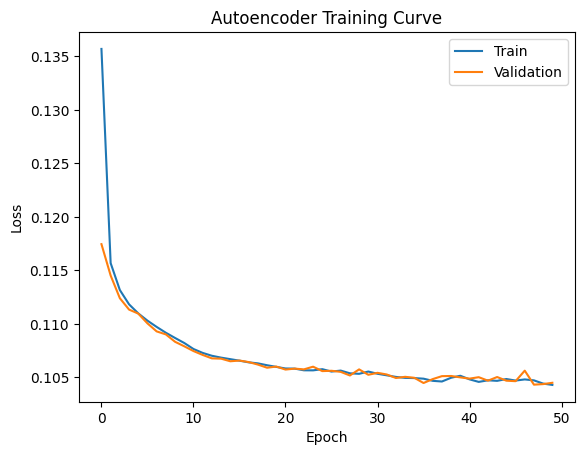

In [4]:
train_df = df[df["train_loss"].notna()]
val_df = df[df["val_loss"].notna()]

plt.figure()
plt.plot(train_df["epoch"], train_df["train_loss"], label="Train")
plt.plot(val_df["epoch"], val_df["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Autoencoder Training Curve")
plt.show()

### Looking at default autoencoder embeddings

During embedding extraction, we stop halfway- 
The training pipeline goes from a patch to an encoder to the embedding then decoded back to reconstruction.
When we do the embedding extraction we do not decode back to reconstruction.
These embeddings are vectors that describe the local texture and radiance patterns around a pixel- these are represented as ae0, ae1, ..., ae7 that the autoencoder discovered (because we chose to go down to 8)

Different embedding sizes:
by picking a small value (4 or 8), we are pretty aggressive in compressing the information so we are getting only the most essential structure; picking a larger value (16, 32, 64) expresses more features but it likely stores some uncecessary and unhelpful information.

We could run PCA on the embeddings and look for clusters?

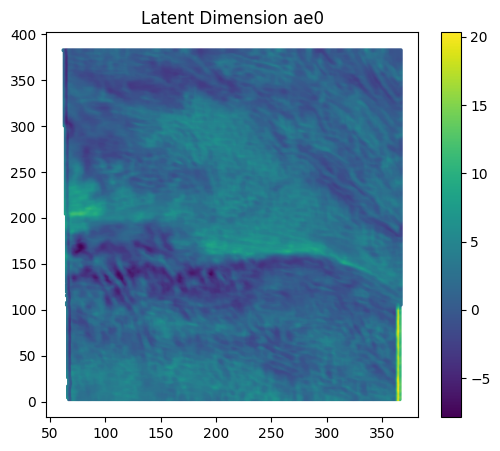

In [5]:

df_im1 = pd.read_csv("../data/image1_ae.csv")

plt.figure(figsize=(6,5))
plt.scatter(df_im1["x"], df_im1["y"], c=df_im1["ae0"], s=1)
plt.colorbar()
plt.title("Latent Dimension ae0")
plt.show()

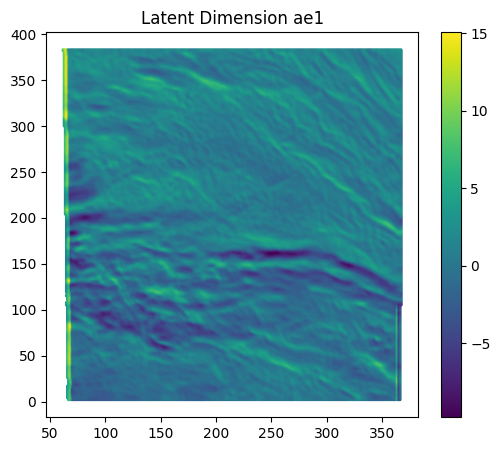

In [6]:
plt.figure(figsize=(6,5))
plt.scatter(df_im1["x"], df_im1["y"], c=df_im1["ae1"], s=1)
plt.colorbar()
plt.title("Latent Dimension ae1")
plt.show()

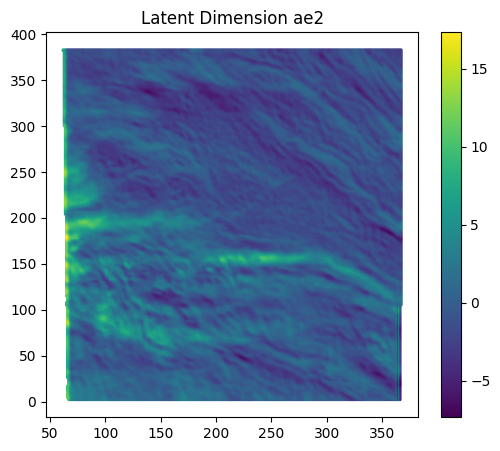

In [7]:
plt.figure(figsize=(6,5))
plt.scatter(df_im1["x"], df_im1["y"], c=df_im1["ae2"], s=1)
plt.colorbar()
plt.title("Latent Dimension ae2")
plt.show()

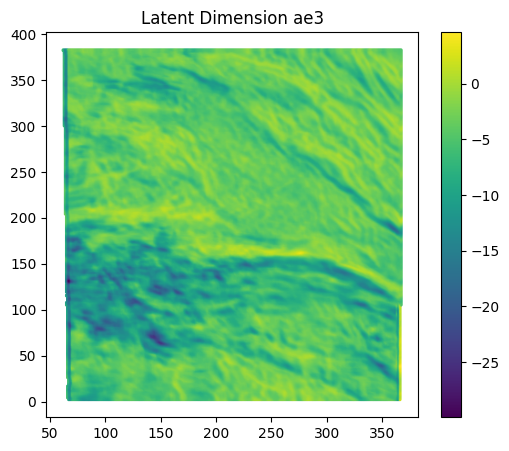

In [8]:
plt.figure(figsize=(6,5))
plt.scatter(df_im1["x"], df_im1["y"], c=df_im1["ae3"], s=1)
plt.colorbar()
plt.title("Latent Dimension ae3")
plt.show()

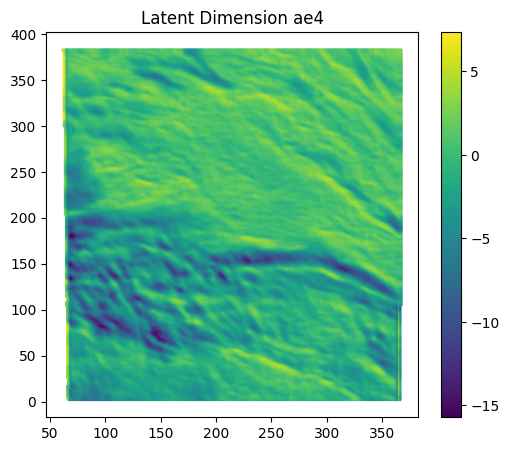

In [9]:
plt.figure(figsize=(6,5))
plt.scatter(df_im1["x"], df_im1["y"], c=df_im1["ae4"], s=1)
plt.colorbar()
plt.title("Latent Dimension ae4")
plt.show()

Could only get like 50 images to work at once so I went in and added a max_images parameter to the max_data so that the images would not overwhelm it all; i can change this later then if it ends up being able to take more; also added the parameter to run_autoencoder and deafult.yamls

Tried it again and was able to get up to 60 images!

Looking at the embedding dimesnisons map


In [10]:
height = int(df_im1["y"].max()) + 1
width = int(df_im1["x"].max()) + 1

img = np.zeros((height,width))

for _,row in df_im1.iterrows():
    img[int(row.y),int(row.x)] = row["ae0"]

Text(0.5, 1.0, 'Embedding dimension ae0')

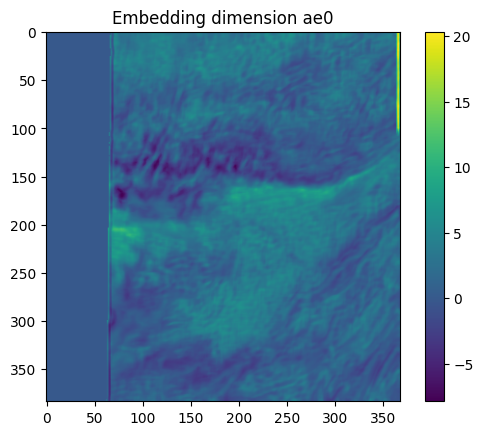

In [11]:
plt.imshow(img)
plt.colorbar()
plt.title("Embedding dimension ae0")

### Autoencoder pipline work

In [12]:
import torch
from data import make_data


In [13]:
# load one file
file = np.load("../data/image_data/O002539.npz")
arr = file["arr_0"]

In [14]:
# reshape 
y = arr[:, 0].astype(int)
x = arr[:, 1].astype(int)

features = arr[:, 2:10]  # 8 features

# image dimensions
height = y.max() + 1
width = x.max() + 1

print(height, width)

384 367


In [15]:
# make multichannel image
image = np.zeros((8, height, width))

for i in range(len(arr)):
    image[:, y[i], x[i]] = features[i]

print(image.shape)

(8, 384, 367)


In [16]:
# get a 9x9 patch
center_y = height // 2
center_x = width // 2

patch = image[:, 
              center_y-4:center_y+5, 
              center_x-4:center_x+5]

print(patch.shape)

(8, 9, 9)


In [17]:
patch = torch.tensor(patch).float().unsqueeze(0)
print(patch.shape)

torch.Size([1, 8, 9, 9])


In [18]:
import torch.nn as nn

nn.Conv2d(in_channels in, out_channels, kernel_size, padding, stride)
- in_channels: how many input feature maps are coming in - we have 8, the 3 constructed features and the 5 radiances
- out_channels: how many filtes we want to learn; this changes depth, not the width or height
- kernel_size: size of the sliding filter, 3 means a 3x3 filter that will span all input channels; small kernels learn more local paatterns and captures edges and have fewer parameters; a larger kernel can more easily overfit 
- padding: controls whether we add zeros around the border; without a 9x9 input and 3x3 kernel gives a 7x7 output (9-3 + 1); by adding 1 zero pixel around it we get a 11x11 input so with a 3x3 kernel we get 9x9 out still; this prevents it from shrinking; general rule is (kernel-1)/2
- stride would help us downsample but we don't need to do that


In [19]:
# define the encoder
encoder_conv = nn.Sequential(
    nn.Conv2d(8, 16, kernel_size=3, padding = 1),
    nn.ReLU(),
    nn.Conv2d(16, 32, kernel_size=3, padding=1),
    nn.ReLU(),
)

# make 8 go up to 32 by having two conv2d layers
x = encoder_conv(patch)
print(x.shape)

torch.Size([1, 32, 9, 9])


reLU is an activation function that sets negative values to zero and keeps postive values unchanged- this helps the network learn nonlinear relationships

we still need to flatten the image, but by doing the covolutionary steps first, we now preserve each of the pixels "location"

In [20]:
flatten = nn.Flatten()
fc = nn.Linear(32*9*9, 8) # sizes after encoding

z = fc(flatten(x))
print(z.shape) # now makes it from 32x9x9 to 8

torch.Size([1, 8])


In [21]:
# test the decoder
decoder_fc = nn.Linear(8, 32*9*9)

y = decoder_fc(z)
y = y.view(1, 32, 9, 9) # make it back to the dimensions we want

decoder_conv = nn.Sequential(
    nn.Conv2d(32, 16, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.Conv2d(16, 8, kernel_size=3, padding=1),
)


In [22]:
recon = decoder_conv(y)
print(recon.shape) # back into the original size

torch.Size([1, 8, 9, 9])


In [23]:
#F.mse_loss(batch, decoded)

for the loss funtion (mse), if reconsturction is perfect( x = x_hat) then out loss is 0, and if it is poor, this value increases; the autoencoder lears which embeddings lead to lower loss and allow for good reconstruction.

other losses to consider:
- L1 loss (more robust)
- sparsity penalties

### exploring first convolutoin autoencoder run
10 photos on 30 epochs - version 10

In [24]:
df = pd.read_csv("lightning_logs/version_10/metrics.csv")

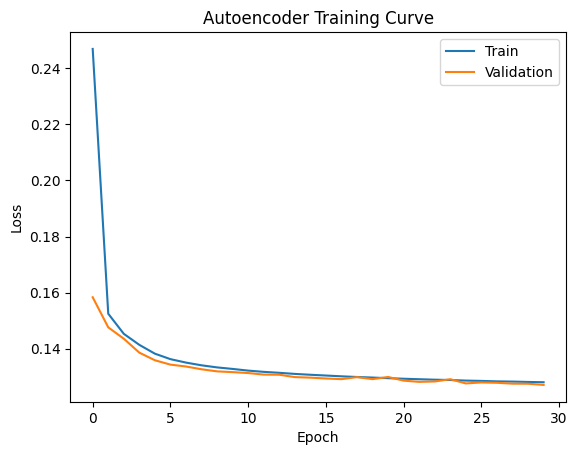

In [25]:
train_df = df[df["train_loss"].notna()]
val_df = df[df["val_loss"].notna()]

plt.figure()
plt.plot(train_df["epoch"], train_df["train_loss"], label="Train")
plt.plot(val_df["epoch"], val_df["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Autoencoder Training Curve")
plt.show()

Current questions I have:
- how do I know after run_embeddings which images correspond to what? I should probably rename the images based off the npz file
- how can I ensure that the 3 labeled images are always embedded?
- am I currently training on only the first 50 images and if so should I be randomizing this?
- am I randomizing the patches and should that be happening?
    I feel like the patches being randomized is good because it is observing independent patches because it already has more information around it that it is learning but this could lead to some parts of a patch being included in a validation set as well

### compare 8 to 16 embeddings

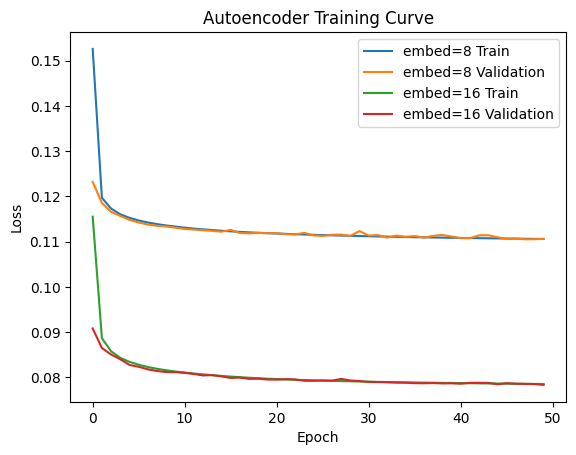

In [38]:

m8 = pd.read_csv("lightning_logs/version_11/metrics.csv")
m16 = pd.read_csv("lightning_logs/version_12/metrics.csv")

train_m8 = m8[m8["train_loss"].notna()]
val_m8 = m8[m8["val_loss"].notna()]
train_m16 = m16[m16["train_loss"].notna()]
val_m16 = m16[m16["val_loss"].notna()]

plt.figure()
plt.plot(train_m8["epoch"], train_m8["train_loss"], label="embed=8 Train")
plt.plot(val_m8["epoch"], val_m8["val_loss"], label="embed=8 Validation")
plt.plot(train_m16["epoch"], train_m16["train_loss"], label="embed=16 Train")
plt.plot(val_m16["epoch"], val_m16["val_loss"], label="embed=16 Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Autoencoder Training Curve")
plt.show()

Checking reconstruction

In [6]:
checkpoint = torch.load("checkpoints/conv1-epoch=027.ckpt", map_location="cpu")
checkpoint_8 = torch.load("checkpoints/conv_8emb-epoch=049.ckpt", map_location="cpu")
checkpoint_16 = torch.load("checkpoints/best_emb16-epoch=067.ckpt", map_location="cpu")

model = Autoencoder(patch_size=9, embedding_size=16)
model.load_state_dict(checkpoint_16["state_dict"])
model.eval()

Autoencoder(
  (encoder_conv): Sequential(
    (0): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
  )
  (encoder_fc): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2592, out_features=16, bias=True)
  )
  (decoder_fc): Sequential(
    (0): Linear(in_features=16, out_features=2592, bias=True)
    (1): ReLU()
  )
  (decoder_conv): Sequential(
    (0): Unflatten(dim=1, unflattened_size=(32, 9, 9))
    (1): Conv2d(32, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (2): ReLU()
    (3): Conv2d(16, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
)

In [7]:
def make_data_single(filepath, patch_size=9):
    """Load and patch a single .npz image file."""
    # handle both a filepath string or an already-loaded npz object
    if isinstance(filepath, str):
        npz_data = np.load(filepath)
    else:
        npz_data = filepath
        
    key = list(npz_data.files)[0]
    data = npz_data[key]
    if data.shape[1] == 11:
        data = data[:, :-1]  # remove labels

    ys = data[:, 0].astype(int)
    xs = data[:, 1].astype(int)
    miny, minx = ys.min(), xs.min()
    height = int(ys.max() - miny + 1)
    width = int(xs.max() - minx + 1)

    nchannels = data.shape[1] - 2
    image = np.zeros((nchannels, height, width))
    for c in range(nchannels):
        image[c, ys - miny, xs - minx] = data[:, c + 2]

    # normalize
    means = image.mean(axis=(1, 2), keepdims=True)
    stds = image.std(axis=(1, 2), keepdims=True) + 1e-8
    image = (image - means) / stds

    pad_len = patch_size // 2
    img_mirror = np.pad(image, ((0,0),(pad_len,pad_len),(pad_len,pad_len)), mode="reflect")

    patches = []
    for y, x in zip(ys, xs):
        y_idx = int(y - miny + pad_len)
        x_idx = int(x - minx + pad_len)
        patch = img_mirror[:, y_idx-pad_len:y_idx+pad_len+1, x_idx-pad_len:x_idx+pad_len+1]
        patches.append(patch.astype(np.float32))

    return data, patches

In [8]:
data = np.load("../data/image_data/O002539.npz")
key = list(data.files)[0]
img = data[key]

patch = img[0,2:]

In [14]:
# create a patch
image_path = "../data/image_data/O013490.npz"
images_long, patches = make_data_single(image_path, patch_size=9)

patch = patches[8]
patch_tensor = torch.tensor(patch).float().unsqueeze(0)

In [15]:
# reconstruct
with torch.no_grad():
    reconstructed = model(patch_tensor)

reconstructed = reconstructed.squeeze().numpy()
patch_np = patch_tensor.squeeze().numpy()

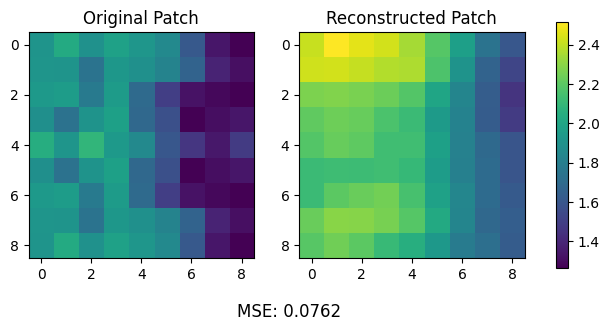

In [16]:
mse = float(((reconstructed - patch_np) ** 2).mean())
vmin = min(patch_np[0].min(), reconstructed[0].min())
vmax = max(patch_np[0].max(), reconstructed[0].max())

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(patch_np[0], vmin=vmin, vmax=vmax)
axes[0].set_title("Original Patch")
im = axes[1].imshow(reconstructed[0], vmin=vmin, vmax=vmax)
axes[1].set_title("Reconstructed Patch")
fig.colorbar(im, ax=axes, shrink=0.8)
fig.suptitle(f"MSE: {mse:.4f}", x=0.45, y=0.1)
plt.show()

### patch randomization?
To avoid data leakage, we want to keep patches from the same image together- they either all go to training or they all go to validation. This way the area around pixels that would overlap are not ending up in training and in validation

In [17]:
images_long, patches = make_data(patch_size=9, max_images=5)

done reshaping images
working on image 0


In [18]:
print(len(patches)) # matches number of images
print(len(patches[0])) # matches number of pixels in one image
print(patches[0][0].shape) # shape of one patch


5
115465
(8, 9, 9)


If we get length of all loaded patches we will see (# images) * (# pixels)
If we get length of patches then we get number of images

then we can define a splitting index based off wehre 80% of the images are (using int will round)

### Adam optimization (of torch)
lr: learning rate, default 1e-3
betas:
weight decay:
dropout:

ae_emb8.yaml with best_emb8-epoch=072.ckpt corresponds to lightning_log 15
